# Soft labels: how much do humans disagree, and does it change the verdict?

A label is usually a single class, but a label can also be a *distribution*: the share of annotators who
chose each class. This notebook evaluates image classifiers against the distribution of human answers
instead of against one label per image, and asks three questions. How much do the annotators disagree? Do
the conclusions about the models change when the reference is soft? And how much of the models' error is
on images where the humans themselves are unsure?

The reference is **CIFAR-10H**, in which about 50 annotators labelled each of the 10,000 images of the
CIFAR-10 test set. The models are the ResNet-32 classifiers of notebook 06, evaluated on the same test set.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import hashlib
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aggmetrics import IndicatorMatrix, marginal_defect, soft_cells

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## The data

**Human labels.** CIFAR-10H (Peterson, Battleday, Griffiths and Russakovsky, ICCV 2019) gives, for every
test image, the share of annotators who chose each of the ten classes. It is distributed under the
**CC BY-NC-SA 4.0** licence (non-commercial use, with attribution), so it is **not** part of this repository:
the notebook downloads the file from the authors' repository at a fixed commit and checks its hash. If
you use it, cite the paper and keep to that licence.

**Model outputs.** The softmax probabilities of ten ResNet-32 models trained on the long-tailed CIFAR-10-LT
(cross-entropy and logit adjustment, five seeds each, as in notebook 06), on the CIFAR-10 test set. They are
in the repository, with the predictions.

In [3]:
CIFAR10H_URL = ("https://raw.githubusercontent.com/jcpeterson/cifar-10h/"
                "389f22d9d300ec71a4c44735d46f550c94b957ab/data/cifar10h-probs.npy")
CIFAR10H_SHA256 = "436ae98620e00073f9d08585ac870573b588853e7af9f54eb1647408114af77d"

raw = urllib.request.urlopen(CIFAR10H_URL, timeout=60).read()
assert hashlib.sha256(raw).hexdigest() == CIFAR10H_SHA256, "unexpected file"
human = np.load(io.BytesIO(raw))             # (10000, 10): share of annotators choosing each class

REPO = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/cifar10lt/"
def load(name):
    local = Path("../data/cifar10lt") / name
    return np.load(local if local.exists() else io.BytesIO(urllib.request.urlopen(REPO + name, timeout=60).read()))

preds, probs = load("predictions.npz"), load("probabilities.npz")
loss, seed = probs["loss"], probs["seed"]
assert (preds["loss"] == loss).all() and (preds["seed"] == seed).all()
y = preds["y_test"].astype(int)              # the original CIFAR-10 label of each test image
n = len(y)

print("human labels:", human.shape, "| every row sums to 1:", bool(np.allclose(human.sum(axis=1), 1)))
agree = (human.argmax(axis=1) == y).mean()
print(f"the most chosen human class equals the CIFAR-10 label for {agree:.4f} of the images "
      f"({int((human.argmax(axis=1) != y).sum())} images differ)")

human labels: (10000, 10) | every row sums to 1: True
the most chosen human class equals the CIFAR-10 label for 0.9921 of the images (79 images differ)


The human majority agrees with the original label for 99.2% of the images, which also confirms that the two
files are aligned image by image (a misalignment would give about 10%).

## How much do the annotators disagree?

For each image, the share of annotators who chose the most popular class:

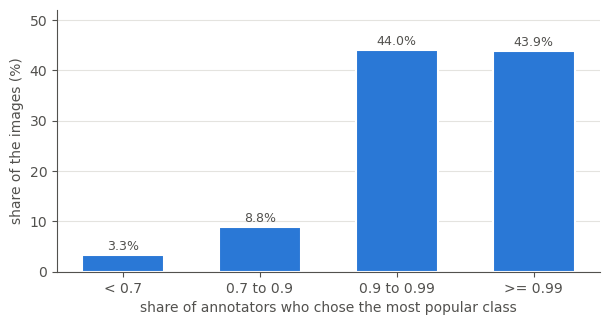

mean share of the most popular class: 0.9544


In [4]:
top = human.max(axis=1)
edges = [0.7, 0.9, 0.99]
bins = np.digitize(top, edges)                                   # 0: <0.7, 1: 0.7-0.9, 2: 0.9-0.99, 3: >=0.99
bin_labels = ["< 0.7", "0.7 to 0.9", "0.9 to 0.99", ">= 0.99"]
counts = np.bincount(bins, minlength=4)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(4), 100 * counts / n, color=BLUE, edgecolor="white", linewidth=1.5, width=0.6)
for i, c in enumerate(counts):
    ax.text(i, 100 * c / n + 1, f"{100 * c / n:.1f}%", ha="center", color=INK2, fontsize=9)
ax.set_xticks(range(4))
ax.set_xticklabels(bin_labels)
ax.set_xlabel("share of annotators who chose the most popular class")
ax.set_ylabel("share of the images (%)")
ax.set_ylim(0, 52)
ax.grid(axis="x", visible=False)
plt.show()

print("mean share of the most popular class:", round(float(top.mean()), 4))

The annotators are nearly unanimous: 44% of the images get at least 99% of the votes for one class and another
44% get between 90% and 99%. Only 3% of the images are really contested (under 70%). On this dataset a hard label
is close to the truth most of the time, and the distribution matters for a minority of the images.

## Evaluating against a distribution

With a soft reference, the cell matrices are built with a t-norm instead of a Boolean "and": with the **product**
t-norm, the true positives of a class are $\sum_i q_{ik}\,p_{ik}$, where $q$ is the share of annotators and $p$
the probability given by the model. Every measure of the library then works unchanged, because the cells are
still numbers that add up in the same way. On a multiclass problem with soft labels, each class is a column of
the matrix, so the task is `multilabel`:

In [5]:
def hard_im(i):
    return IndicatorMatrix(y, preds["pred_test"][i].astype(int), task="multiclass", n_classes=10)

def soft_im(i):
    return IndicatorMatrix(human, probs["prob_test"][i].astype(float), task="multilabel", tnorm="product")

rows = []
for i in range(len(loss)):
    h, s = hard_im(i), soft_im(i)
    # with the product t-norm and soft labels that sum to 1, micro-recall is the average agreement
    assert np.isclose(s.compute("recall", "micro"), (human * probs["prob_test"][i].astype(float)).sum() / n)
    rows.append(dict(model=loss[i], seed=int(seed[i]),
                     accuracy_hard=h.accuracy(), accuracy_soft=s.compute("recall", "micro"),
                     macro_recall_hard=h.compute("recall", "macro"), macro_recall_soft=s.compute("recall", "macro"),
                     macro_F1_hard=h.compute("f1", "macro"), macro_F1_soft=s.compute("f1", "macro")))
runs = pd.DataFrame(rows)
runs.groupby("model").mean(numeric_only=True).drop(columns="seed").T.round(4)

model,ce,logit_adj
accuracy_hard,0.6611,0.7090
accuracy_soft,0.6375,0.6845
macro_recall_hard,0.6611,0.7090
macro_recall_soft,0.6396,0.6862
macro_F1_hard,0.6500,0.7060
macro_F1_soft,0.6264,0.6815


The soft values are about 0.024 below the hard ones for both models, and the ranking is the same on every
measure: logit adjustment is ahead of cross-entropy. The reason for the gap is that the soft score also charges the
model for its own uncertainty and for the annotators' disagreement, while an `argmax` against a single label
charges only a wrong class.

How far are the models from the best a soft evaluation can give? Two reference points:

In [6]:
ceilings = pd.Series({
    "model that always names the human majority with certainty": float(top.mean()),
    "model that reproduces the human distribution exactly": float((human ** 2).sum(axis=1).mean()),
    "cross-entropy model (mean of 5 seeds)": runs[runs.model == "ce"].accuracy_soft.mean(),
    "logit-adjustment model (mean of 5 seeds)": runs[runs.model == "logit_adj"].accuracy_soft.mean(),
}, name="soft accuracy").round(3)
ceilings.to_frame()

,soft accuracy
model that always names the human majority with certainty,0.954
model that reproduces the human distribution exactly,0.925
cross-entropy model (mean of 5 seeds),0.637
logit-adjustment model (mean of 5 seeds),0.685


A model that names the human majority with certainty gets 0.954, and one that reproduces the distribution gets
0.925, which is below 1 because the humans disagree among themselves: their disagreement costs between 0.05
and 0.08 of the maximum score. The models are at 0.64 and 0.68, so the gap to those ceilings, between 0.24
and 0.32, is several times larger. The soft reference does not explain the error. The next section checks that
directly.

One caution about this measure. With the product t-norm the soft accuracy is $\sum_k q_k\,p_k$, which is
linear in the model's probabilities, so it is maximised by putting all the probability on the most voted class.
That is why a model that names the majority with certainty (0.954) scores above one that reproduces the
distribution (0.925): the measure rewards a good *decision*, not calibration. To reward calibration, use a proper
scoring rule such as the log-loss or the Brier score, which the library does not compute.

## Where do the models err: on the images humans find hard?

Group the images by how much the annotators agree, and measure the error rate of each model (the share of images
where its `argmax` differs from the original label), averaged over the five seeds:

                ce  logit_adj  images  share of all errors (ce)  share of all errors (logit_adj)
< 0.7        0.508      0.495     327                     0.049                            0.056
0.7 to 0.9   0.429      0.418     884                     0.112                            0.127
0.9 to 0.99  0.359      0.308    4396                     0.466                            0.466
>= 0.99      0.288      0.233    4393                     0.374                            0.351


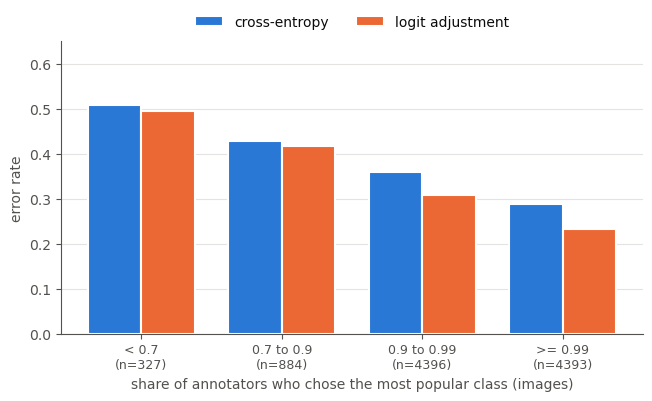

images where under 90% of the annotators agree: 12.1% of the images, 16.1% of the errors of the cross-entropy models


In [7]:
err = {name: np.mean([preds["pred_test"][i] != y for i in range(len(loss)) if loss[i] == name], axis=0)
       for name in ("ce", "logit_adj")}

table = pd.DataFrame({name: [err[name][bins == b].mean() for b in range(4)] for name in err}, index=bin_labels)
table["images"] = counts
for name in err:
    table[f"share of all errors ({name})"] = [err[name][bins == b].sum() / err[name].sum() for b in range(4)]
print(table.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(4)
w = 0.38
ax.bar(x - w / 2, table["ce"], w, color=BLUE, edgecolor="white", linewidth=1.5, label="cross-entropy")
ax.bar(x + w / 2, table["logit_adj"], w, color=ORANGE, edgecolor="white", linewidth=1.5, label="logit adjustment")
ax.set_xticks(x)
ax.set_xticklabels([f"{lab}\n(n={c})" for lab, c in zip(bin_labels, counts)], fontsize=9)
ax.set_xlabel("share of annotators who chose the most popular class (images)")
ax.set_ylabel("error rate")
ax.set_ylim(0, 0.65)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.show()

ambiguous = bins <= 1
print(f"images where under 90% of the annotators agree: {ambiguous.mean():.1%} of the images, "
      f"{err['ce'][ambiguous].sum() / err['ce'].sum():.1%} of the errors of the cross-entropy models")

The error rate does rise as the humans agree less: for the cross-entropy models it goes from 0.29 on the
near-unanimous images to 0.51 on the contested ones. But those contested images are few, and most of the errors are
elsewhere: **84% of the errors of the cross-entropy models (82% for logit adjustment) are on images where at least
90% of the annotators agree**. The models are wrong mainly on images that people recognise easily, so label
ambiguity is not what limits them here. That would be a different story on a dataset with noisier labels, and this
is the kind of check that tells the two apart.

## Why the product t-norm

The product is the only t-norm under which the soft cells keep the totals of the labels: the true positives and
false negatives of a class add up to the number of annotator votes for it, whatever the model says. With the other
two common t-norms, the cells imply a different number of positives than the humans gave. For the first model:

In [8]:
p0 = probs["prob_test"][0].astype(float)
human_totals = human.sum(axis=0)

deviation = {}
for name in ("product", "godel", "lukasiewicz"):
    tp, fp, fn, tn = soft_cells(human, p0, name)
    deviation[name] = 100 * ((tp + fn).sum(axis=0) / human_totals - 1)
dev = pd.DataFrame(deviation).round(2)
dev.index.name = "class"
dev.columns = [f"{c} (marginal defect {marginal_defect(c):.1f})" for c in dev.columns]
print("positives implied by the cells (true positives + false negatives) against the annotator votes, in %:")
dev

positives implied by the cells (true positives + false negatives) against the annotator votes, in %:


,product (marginal defect 0.0),godel (marginal defect 0.5),lukasiewicz (marginal defect 0.5)
class,,,
0,0.0,0.78,-0.78
1,0.0,0.78,-0.78
2,0.0,2.07,-2.07
3,0.0,3.20,-3.20
4,0.0,2.50,-2.50
5,0.0,1.78,-1.78
6,0.0,1.20,-1.20
7,0.0,0.66,-0.66
8,0.0,0.53,-0.53


With the product the totals are exact. The Gödel t-norm overstates the positives of every class (by up to 3.2%)
and the Łukasiewicz t-norm understates them (by up to 3.2%), so a recall computed from those cells divides by a
number that is not the number of votes. The distortion is small here, where most of the human labels are nearly
one-hot. The simulation below shows how it grows with the disagreement.

## When would the verdict change? A simulation

On CIFAR-10H the soft reference changes nothing, because the humans nearly always agree. To see when it would,
here is a **simulation, built to make the mechanism visible; it is not evidence about real data**. Two classes,
10,000 images, and for each image a probability $q_i$ that an annotator chooses class 1: for most images $q_i$ is
near 0 or 1, and for a share of them (the *ambiguous* images) it is near 0.5.

- The **soft reference** is the share of 50 simulated annotators who chose class 1.
- The **hard label** comes from a *single* annotator with a bias: on ambiguous images the annotator leans
  toward class 1, by up to `bias` in probability.
- **Model A** learned that annotator: its probabilities follow the annotator's, not the consensus.
  **Model B** follows the consensus $q_i$. Both get the same random error, so they differ only in the bias.

Which model is better, if the question is which one agrees with people?

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def simulate(n=10000, ambiguous_share=0.4, bias=0.2, noise=1.0, annotators=50, seed=0):
    rng = np.random.default_rng(seed)
    ambiguous = rng.random(n) < ambiguous_share
    q = np.where(ambiguous, rng.beta(5, 5, n),                          # near 0.5: humans split
                 np.where(rng.random(n) < 0.5, rng.beta(0.3, 6, n), rng.beta(6, 0.3, n)))   # near 0 or 1
    p_annotator = np.clip(q + bias * 4 * q * (1 - q), 0, 1)             # the biased annotator
    hard = (rng.random(n) < p_annotator).astype(int)                    # the hard label: one annotator
    q_hat = rng.binomial(annotators, q) / annotators                    # the soft label: 50 annotators
    eps = rng.normal(0, noise, n)                                       # the same error for both models
    return dict(q=q, hard=hard, q_hat=q_hat,
                p_A=sigmoid(logit(p_annotator) + eps), p_B=sigmoid(logit(q) + eps))

def bootstrap_ci(d, B=1000, seed=1):
    rng = np.random.default_rng(seed)
    return np.percentile(d[rng.integers(0, len(d), (B, len(d)))].mean(axis=1), [2.5, 97.5])

def compare(sim):
    hard, q_hat = sim["hard"], sim["q_hat"]
    dec = {m: (sim["p_" + m] > 0.5).astype(int) for m in "AB"}
    onehot = {m: np.column_stack([1 - dec[m], dec[m]]).astype(float) for m in "AB"}
    truth = np.column_stack([1 - q_hat, q_hat])
    # the library: hard accuracy against the single annotator, and soft accuracy of the decisions
    # against the 50-annotator distribution, with the product t-norm
    hard_acc = {m: IndicatorMatrix(hard, dec[m], task="multiclass", n_classes=2).accuracy() for m in "AB"}
    soft_acc = {m: IndicatorMatrix(truth, onehot[m], task="multilabel", tnorm="product").compute("recall", "micro")
                for m in "AB"}
    d_hard = (dec["A"] == hard).astype(float) - (dec["B"] == hard).astype(float)
    d_soft = np.where(dec["A"] == 1, q_hat, 1 - q_hat) - np.where(dec["B"] == 1, q_hat, 1 - q_hat)
    assert np.isclose(d_hard.mean(), hard_acc["A"] - hard_acc["B"])
    assert np.isclose(d_soft.mean(), soft_acc["A"] - soft_acc["B"])
    return d_hard, d_soft, dec

sim = simulate()
d_hard, d_soft, dec = compare(sim)
consensus = (sim["q"] > 0.5).astype(int)
d_cons = (dec["A"] == consensus).astype(float) - (dec["B"] == consensus).astype(float)
d_prob = (sim["q_hat"] * sim["p_A"] + (1 - sim["q_hat"]) * (1 - sim["p_A"])
          - sim["q_hat"] * sim["p_B"] - (1 - sim["q_hat"]) * (1 - sim["p_B"]))

rows = []
for name, d in (("hard accuracy, against the single annotator", d_hard),
                ("soft accuracy of the decisions, against the 50 annotators", d_soft),
                ("soft accuracy of the probabilities, against the 50 annotators", d_prob),
                ("hard accuracy against the consensus (unknowable in practice)", d_cons)):
    lo, hi = bootstrap_ci(d)
    rows.append(dict(evaluation=name, A_minus_B=d.mean(), ci_low=lo, ci_high=hi))
differ = dec["A"] != dec["B"]
print(f"the two models decide differently on {int(differ.sum())} of {len(differ)} images; "
      f"{((sim['q'][differ] > 0.3) & (sim['q'][differ] < 0.7)).mean():.0%} of those are contested (q between 0.3 and 0.7)")
pd.DataFrame(rows).set_index("evaluation").round(4)

the two models decide differently on 1151 of 10000 images; 82% of those are contested (q between 0.3 and 0.7)


,A_minus_B,ci_low,ci_high
evaluation,,,
"hard accuracy, against the single annotator",0.0375,0.0305,0.0444
"soft accuracy of the decisions, against the 50 annotators",-0.0059,-0.0081,-0.0038
"soft accuracy of the probabilities, against the 50 annotators",0.0014,0.0005,0.0023
hard accuracy against the consensus (unknowable in practice),-0.0147,-0.0215,-0.0081


Against the single biased annotator, model A looks clearly better: +3.75 points of accuracy, with an interval
well above zero. Against the 50 annotators the verdict reverses: the soft accuracy of the decisions favours B,
by 0.6 points, with an interval that excludes zero. The consensus, which cannot be observed in practice, agrees:
B is better. The hard evaluation credited A for imitating one annotator's habit.

The size of the reversal is small, and the reason is the point of soft labels: the models decide differently on
12% of the images, and over 80% of those are contested images, where the humans themselves are split, so a
decision either way costs little in soft terms. The hard evaluation charges a full point for each.

The soft accuracy of the *probabilities* barely separates the models (+0.0014): as seen above, that measure is
linear in the probabilities and rewards decisiveness, and the two models are equally decisive. To measure the
decisions against a distribution, as in the second row, evaluate one-hot predictions with the soft reference.

How does this depend on the bias of the annotator and on how many images are ambiguous? Sweeping the bias, for
two shares of ambiguous images:

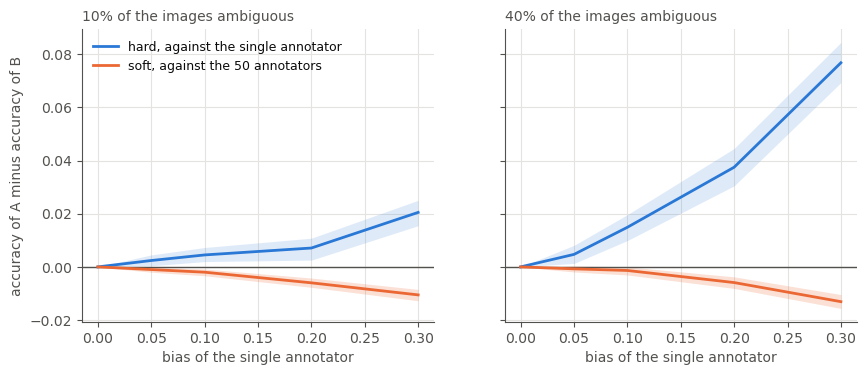

,ambiguous_share,bias,hard,hard_lo,hard_hi,soft,soft_lo,soft_hi,verdict_reverses
0,0.1,0.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,False
1,0.1,0.05,0.0024,0.0004,0.0045,-0.0010,-0.0020,-0.0001,True
2,0.1,0.10,0.0045,0.0020,0.0073,-0.0020,-0.0033,-0.0008,True
3,0.1,0.20,0.0071,0.0025,0.0108,-0.0060,-0.0077,-0.0042,True
4,0.1,0.30,0.0205,0.0155,0.0251,-0.0105,-0.0128,-0.0085,True
5,0.4,0.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,False
6,0.4,0.05,0.0047,0.0013,0.0081,-0.0007,-0.0019,0.0004,False
7,0.4,0.10,0.0149,0.0099,0.0197,-0.0014,-0.0030,0.0000,False
8,0.4,0.20,0.0375,0.0305,0.0446,-0.0059,-0.0081,-0.0037,True
9,0.4,0.30,0.0768,0.0693,0.0845,-0.0131,-0.0156,-0.0104,True


In [10]:
biases = [0.0, 0.05, 0.1, 0.2, 0.3]
sweep_rows = []
for share in (0.1, 0.4):
    for b in biases:
        d_h, d_s, _ = compare(simulate(ambiguous_share=share, bias=b))
        (hl, hh), (sl, sh) = bootstrap_ci(d_h, B=500), bootstrap_ci(d_s, B=500)
        sweep_rows.append(dict(ambiguous_share=share, bias=b, hard=d_h.mean(), hard_lo=hl, hard_hi=hh,
                               soft=d_s.mean(), soft_lo=sl, soft_hi=sh))
sweep = pd.DataFrame(sweep_rows)
sweep["verdict_reverses"] = (sweep.hard_lo > 0) & (sweep.soft_hi < 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, share in zip(axes, (0.1, 0.4)):
    part = sweep[sweep.ambiguous_share == share]
    ax.axhline(0, color=INK2, linewidth=1)
    ax.plot(part.bias, part.hard, color=BLUE, label="hard, against the single annotator")
    ax.fill_between(part.bias, part.hard_lo, part.hard_hi, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(part.bias, part.soft, color=ORANGE, label="soft, against the 50 annotators")
    ax.fill_between(part.bias, part.soft_lo, part.soft_hi, color=ORANGE, alpha=0.2, linewidth=0)
    ax.set_title(f"{int(100 * share)}% of the images ambiguous", loc="left", fontsize=10, color=INK2)
    ax.set_xlabel("bias of the single annotator")
axes[0].set_ylabel("accuracy of A minus accuracy of B")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
plt.show()
sweep.round(4)

With no bias there is nothing to find, as it must be. As the bias grows, the hard evaluation credits model A
more and more, up to 7.7 points with 40% ambiguous images and the largest bias, while the soft evaluation moves
the other way by between 0.1 and 1.3 points. The reversal is statistically clear, with the two intervals on
opposite sides of zero, in 6 of the 8 cells that have a bias. In the other two (40% ambiguous, small bias) the
soft interval touches zero: the soft evaluation does not say B is better, only that the advantage of A has
gone. The soft reference does not always reverse the verdict. It does when the hard label carries a habit of
its own, and then the hard evaluation overstates the habit by far more than the soft one corrects it.

The distortion of the other t-norms also depends on the disagreement. The same simulation, varying the share of
ambiguous images, with the soft cells of model B:

In [11]:
rows = []
for share in (0.05, 0.1, 0.2, 0.4, 0.8):
    s_ = simulate(ambiguous_share=share, bias=0.0)
    q_hat, p = s_["q_hat"], s_["p_B"]
    truth = np.column_stack([1 - q_hat, q_hat])
    probs2 = np.column_stack([1 - p, p])
    row = {"ambiguous share": share}
    for name in ("product", "godel", "lukasiewicz"):
        tp, fp, fn, tn = soft_cells(truth, probs2, name)
        row[name] = 100 * ((tp + fn)[:, 1].sum() / q_hat.sum() - 1)
    rows.append(row)
pd.DataFrame(rows).set_index("ambiguous share").round(2)

,product,godel,lukasiewicz
ambiguous share,,,
0.05,0.0,9.16,-9.16
0.10,0.0,11.62,-11.62
0.20,0.0,16.61,-16.61
0.40,0.0,25.98,-25.98
0.80,0.0,45.03,-45.03


The table gives the positives of class 1 implied by the cells, as a percentage over the annotator votes. The
product keeps the totals exactly, and the Gödel and Łukasiewicz t-norms drift further from them as the share of
ambiguous images grows (here the model's own probabilities are soft too, which adds to the distortion). So the
choice of t-norm matters little for a dataset like CIFAR-10H and a lot for one where annotators often disagree.

## What to report

- When the reference is a distribution, **say so** and use a t-norm; the **product** is the one that keeps the
  totals of the labels. Evaluate with the same measures and operators as with hard labels.
- Report the **hard** and the **soft** value and the ceilings. Here the soft value is about 0.024 lower and
  does not change the ranking of the models, which is a finding worth stating.
- **Check where the error is** before attributing it to label noise: group the images by annotator agreement.
  On CIFAR-10 most of the error is on images the humans agree about.
- A **hard label from one annotator carries that annotator's habits**, and a model trained on the same source
  can be credited for them. A soft reference from many annotators is the check; in the simulation it reverses
  the verdict when the habit is strong and the images are ambiguous enough.
- To score *decisions* against a distribution, evaluate one-hot predictions with the soft reference; the soft
  accuracy of probabilities rewards decisiveness, not calibration.
- Soft labels matter most when the annotators disagree often; with nearly unanimous labels, as in CIFAR-10H,
  the distribution adds little to a hard evaluation.

Next: pixel-level measures for segmentation, and custom measures.